In [1]:
using Pkg
# adjust toktox_path to match the location of your cloned TokToxStability repo
toktox_path = "/Users/adrianaghiozzi/.julia/dev/TokToxStability"
Pkg.activate(toktox_path)
Pkg.instantiate()

  Activating project at `~/.julia/dev/TokToxStability`


In [2]:
venv_python = joinpath(toktox_path, ".venv", "bin", "python")
if !isfile(venv_python)
    run(`$(joinpath(toktox_path, "setup_venv.sh"))`)
end

In [3]:
ENV["JULIA_CONDAPKG_BACKEND"] = "Null"
ENV["JULIA_PYTHONCALL_EXE"] = venv_python

"/Users/adrianaghiozzi/.julia/dev/TokToxStability/.venv/bin/python"

In [4]:
using Revise
using TokToxStability
using Plots
using DataFrames
using PythonCall

In [5]:
# only call this once per kernel session
myOFT = TokToxStability.make_oft_env()   


#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        v26.6
Development branch:  main
Revision id:         f5ab95b

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------



Python: <OpenFUSIONToolkit._core.OFT_env object at 0x119b38830>

In [6]:
# An example kinetic EFIT and corresponding geqdsk for DIII-D shot 147131 are provided in cases/D3D
# load_default_settings_tearing sets up GPECSettings for the tearing workflow: ideal-MHD Delta'
# (kinetic_factor=0.0) plus the Glasser/inner-layer inputs (chi_perp, zeff, dc_type, mu_i) that
# compute_glasser_terms needs below.
gpec_settings = TokToxStability.load_default_settings_tearing(1)
kinetic_efit_path = joinpath(pkgdir(TokToxStability), "cases/D3D/g147131.02300_DIIID_KEFIT.kin")
geqdsk_path = joinpath(pkgdir(TokToxStability), "cases/D3D/g147131.02300_DIIID_KEFIT.eqdsk")


"/Users/adrianaghiozzi/.julia/dev/TokToxStability/cases/D3D/g147131.02300_DIIID_KEFIT.eqdsk"

In [7]:
profiles = TokToxStability.read_kinetic_profiles_from_file(kinetic_efit_path)
equilibrium = TokToxStability.read_equilibrium_from_file(geqdsk_path)


TokToxStability.Equilibrium([0.0, 0.0078125, 0.015625, 0.0234375, 0.03125, 0.0390625, 0.046875, 0.0546875, 0.0625, 0.0703125  …  0.9296875, 0.9375, 0.9453125, 0.953125, 0.9609375, 0.96875, 0.9765625, 0.984375, 0.9921875, 1.0], nothing, nothing, 1.69550002, -1.7227961, 1.18663454e6, 76762.0766, [1.08649712 0.0; 1.09147054 0.1; … ; 1.08606136 -0.025; 1.08649712 0.0], [-0.911430759, -0.946775258, -0.976776409, -1.00206207, -1.02318633, -1.04063817, -1.0548491, -1.06619994, -1.07502677, -1.08162616  …  0.171213058, 0.290801074, 0.483881839, 0.671604565, 0.746098232, 0.715833223, 0.616102304, 0.480663723, 0.334205417, 0.20021433], [-620844.41, -605164.368, -590721.145, -577369.417, -564980.938, -553442.532, -542654.324, -532528.173, -522986.299, -513960.063  …  -341873.422, -420296.619, -549904.238, -665250.784, -679899.319, -605373.806, -475780.814, -324936.214, -197176.492, -108641.837])

In [8]:
mygs = TokToxStability.setup_tokamaker_from_file!(:D3D, profiles, equilibrium, myOFT)



**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.574E+01
    # of points  =    8912
    # of edges   =   26573
    # of cells   =   17662
    # of boundary points =     160
    # of boundary edges  =     160
    # of boundary cells  =     160
  Resolution statistics:
    hmin =  8.702E-04
    hrms =  4.833E-02
    hmax =  1.540E-01
  Surface grounded at vertex    1733


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1

 Computing flux BC matrix 
 Inverting real matrix
   Time =    1.7870000000000000E-003
Starting non-linear GS solver
     1 -1.6730E+00 -1.2573E-06  1.4550E-01  1.7610E+00  2.2573E-02 -4.9357E+03
     2 -1.8259E+00 -1.2740E-06  3.1527E-02  1.7614E+00  2.3709E-02  1.4707E+04
     3 -1.9088E+00 -1.2732E-06  6.9955E-03  1.7608E+00  2.4323E-02  1.4288E+04
     4 -1.9485E+00 -1.2681E-06  1.6348E-03  1.7602E+00  2.4649E-02  1.3448E+04
     5 -1.9645E+00 -1.2651E-06

Python: <OpenFUSIONToolkit.TokaMaker._core.TokaMaker object at 0x17e9c4590>

In [9]:
# The gEQDSK files created by TokaMaker at each scan iteration can be saved by setting working_directory
# For a file-less option, set working_directory = nothing, which will save the gEQDSKs to a temporary directory that is deleted after the run
working_directory = nothing

# fractions sets the pressure scaling factors to scan for tearing behavior. This example doesn't
# search for the ideal-MHD beta limit itself (see the ideal_beta_limit_from_files/_from_tmtx
# examples for that) -- just pick a fixed set of fractions to see how Delta' evolves with beta_N.
fractions = [1.0, 1.1, 1.2, 1.3, 1.4, 1.5]

coarse_scan_results = TokToxStability.coarse_scan(mygs, fractions, equilibrium, profiles, gpec_settings; working_directory = working_directory);


Saving gEQDSK: /var/folders/x_/gs_bft6j2fvfl3kr9lc7qlm80000gn/T/jl_vGiibb/f1p0000/tokamaker_f1p0000.geqdsk
Saving gEQDSK: /var/folders/x_/gs_bft6j2fvfl3kr9lc7qlm80000gn/T/jl_qZ2U2D/f1p1000/tokamaker_f1p1000.geqdsk
Saving gEQDSK: /var/folders/x_/gs_bft6j2fvfl3kr9lc7qlm80000gn/T/jl_y47gw0/f1p2000/tokamaker_f1p2000.geqdsk
Saving gEQDSK: /var/folders/x_/gs_bft6j2fvfl3kr9lc7qlm80000gn/T/jl_2mVHAP/f1p3000/tokamaker_f1p3000.geqdsk
Saving gEQDSK: /var/folders/x_/gs_bft6j2fvfl3kr9lc7qlm80000gn/T/jl_K8kUAE/f1p4000/tokamaker_f1p4000.geqdsk
Saving gEQDSK: /var/folders/x_/gs_bft6j2fvfl3kr9lc7qlm80000gn/T/jl_Y9QB1H/f1p5000/tokamaker_f1p5000.geqdsk


In [10]:
# Creates a DataFrame with the results of the scan 
cols = (:fraction, :beta_n, :dW_total, :dW_plasma, :dW_vacuum, :qmax, :msing)
DataFrame([NamedTuple{cols}(r[c] for c in cols) for r in coarse_scan_results])

Row,fraction,beta_n,dW_total,dW_plasma,dW_vacuum,qmax,msing
,Float64,Float64,Float64,Float64,Float64,Float64,Int64
1,1.0,1.5994,0.588607,-2.18005,2.76866,5.47073,4
2,1.1,1.75799,0.49207,-2.46803,2.9601,5.51083,4
3,1.2,1.91634,0.379418,-2.79339,3.17281,5.55129,4
4,1.3,2.07422,0.250244,-3.15502,3.40527,5.59315,4
5,1.4,2.23202,0.104546,-3.55219,3.65674,5.63488,4
6,1.5,2.38951,-0.059668,-3.98535,3.92568,5.67665,4


In [11]:
# Each scan point also carries GPEC's classical linear tearing Delta' matrix (ideal-MHD outer-region
# matching, PEST3 convention), since kinetic_factor=0 in gpec_settings above. It's indexed by rational
# surface, not by mode numbers, so singular_surfaces (the (m, n, q) of each row/column) is carried
# alongside it -- see delta_prime_for_mode below.
coarse_scan_results[1].singular_surfaces

4-element Vector{@NamedTuple{m::Vector{Int64}, n::Vector{Int64}, q::Float64}}:
 (m = [2], n = [1], q = 2.0)
 (m = [3], n = [1], q = 3.0)
 (m = [4], n = [1], q = 4.0)
 (m = [5], n = [1], q = 5.0)

## Glasser stabilization (Delta_eff)

The classical Δ' above is the ideal-MHD outer-region jump alone; the Glasser/chi_parallel-matching
correction (Leuthold et al., "ARC physics basis -- MHD", Sec 4.2.1) folds in the resistive-layer
physics to give `Delta_eff = Delta' - Delta_crit`, a more physically complete tearing criterion.
Since `profiles` was read with `read_kinetic_profiles_from_file` (which picked up the `.kin` file's
`wexb(rad/s)` column into `profiles.omega`), every scan point above already carries a
`glasser_terms` entry -- computed once per point, right when `evaluate_factor` still has the raw
GPEC output in hand.

In [12]:
# Delta_crit and Delta_eff = Delta' - Delta_crit for the 2/1 mode at each scanned point.
[(beta_n=r.beta_n,
  delta_prime_21=TokToxStability.delta_prime_for_mode(r, 2, 1),
  delta_crit_21=TokToxStability.delta_crit_for_mode(r, 2, 1),
  delta_eff_21=TokToxStability.delta_eff_for_mode(r, 2, 1)) for r in coarse_scan_results]

6-element Vector{@NamedTuple{beta_n::Float64, delta_prime_21::Float64, delta_crit_21::Float64, delta_eff_21::Float64}}:
 (beta_n = 1.5994047105104243, delta_prime_21 = 9.560475225494683, delta_crit_21 = 17.73086173613661, delta_eff_21 = -8.170386510641928)
 (beta_n = 1.7579890358083563, delta_prime_21 = 11.033987850681923, delta_crit_21 = 19.664672465228886, delta_eff_21 = -8.630684614546963)
 (beta_n = 1.9163356363077715, delta_prime_21 = 14.465601629017533, delta_crit_21 = 21.68987683503946, delta_eff_21 = -7.224275206021927)
 (beta_n = 2.0742197223919394, delta_prime_21 = 21.482510770361657, delta_crit_21 = 23.688696100972823, delta_eff_21 = -2.2061853306111665)
 (beta_n = 2.2320244331125063, delta_prime_21 = 51.96087424043756, delta_crit_21 = 25.654173703673752, delta_eff_21 = 26.30670053676381)
 (beta_n = 2.389510883456626, delta_prime_21 = -71.4948314668415, delta_crit_21 = 27.65473293284483, delta_eff_21 = -99.14956439968634)

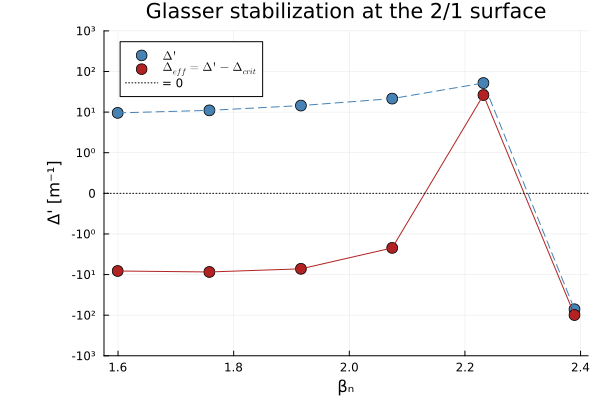

In [13]:
# Delta' vs Delta_eff (Glasser-stabilized) on one symlog axis, 2/1 mode.
TokToxStability.plot_delta_eff_scan(coarse_scan_results, 2, 1)

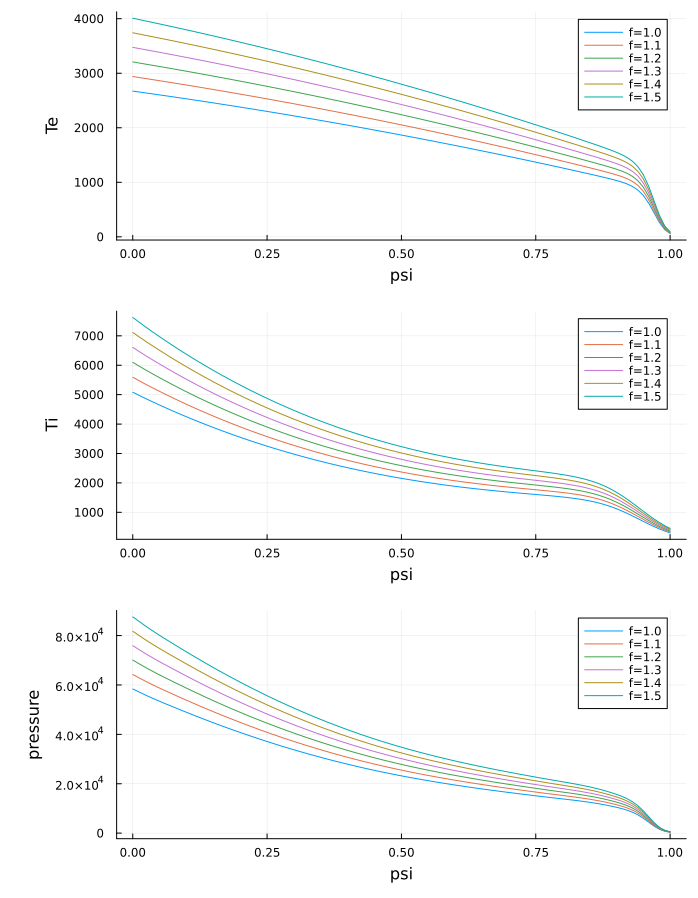

In [14]:
TokToxStability.plot_profiles(coarse_scan_results)


In [19]:
TokToxStability.plot_delta_eff_scan(coarse_scan_results, 3, 2)

ErrorException: plot_delta_eff_scan: no scanned point has a Delta_eff for the 3/2 mode -- either the surface wasn't found, or glasser_terms is missing (profiles.omega must be set when the scan was run).